# Halo mass prediction: scratch vs fine-tuned

Compare segmentation predictions against test HDF5 data on **identical core halos**. The HDF5 `global` dataset contains only `is_central_mass` with shape `(N, M, 1)`.

All mass-dependent plots use `log10(Mpeak)` in dex. **Resolution** means signed log-mass error: `log10(M_pred) - log10(M_true)`; global R² is computed across all matched halos. Bin-wise performance is summarized by RMSE rather than R², because the small target variance in narrow mass bins makes bin-wise R² unstable and frequently negative.

In [1]:
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Evaluation output directories (may be the same folder).
SCRATCH_DIR = Path('/pscratch/sd/v/vmikuni/Omnilearned/outputs/')
FINETUNED_DIR = Path('/pscratch/sd/v/vmikuni/Omnilearned/outputs/')
TEST_DIR = Path('/pscratch/sd/v/vmikuni/datasets/halo/test')

# Restrict the globs if each output directory contains multiple evaluations.
SCRATCH_PATTERN = 'outputs_halo_segmentation_small_scratch*.h5'
FINETUNED_PATTERN = 'outputs_halo_segmentation_small_finetune*.h5'
# For .npz output instead, use 'outputs_*.npz'. Do not load BOTH h5 and npz
# for the same evaluation, because evaluate.py writes the same results twice.

# Position of file_id in the evaluator's loader.dataset.file_paths.
# For a single test file this is automatically {0: file}.
# For several files, check loader.dataset.file_paths ordering and set explicitly.
TEST_FILE_MAP = None  # e.g. {0: 'smdpl.h5', 1: 'bolshoi.h5'}

CORE_ONLY = True
MAX_SCATTER_POINTS = 100_000
SEED = 42
# Save all notebook figures as PNG files.
PLOTS_DIR = Path('plots')
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

def save_plot(fig, name):
    path = PLOTS_DIR / f'{name}.png'
    fig.savefig(path, dpi=180, bbox_inches='tight')
    print(f'Saved {path}')



## Load the evaluated shards and the test source files

The evaluator uses the misleading key `pid` for **ground-truth per-point target** in segmentation mode. The `pid` dataset in the original test HDF5 instead contains one label `1` per cloud; it is **not** the halo-mass target. Original halo truth is in `data_pid`.

For several test files, `file_id` maps to the loader's file ordering. Specify `TEST_FILE_MAP` if necessary. The notebook verifies target alignment rather than silently pairing unrelated clouds.

In [2]:
def evaluation_files(folder, pattern):
    paths = sorted(folder.glob(pattern))
    if not paths:
        raise FileNotFoundError(f'No evaluation outputs matching {pattern!r} in {folder}')
    return paths


def read_eval(path):
    if path.suffix == '.npz':
        with np.load(path) as f:
            return {k: f[k] for k in ('prediction', 'pid', 'file_id', 'row_id')}
    with h5py.File(path) as f:
        return {k: f[k][:] for k in ('prediction', 'pid', 'file_id', 'row_id')}


def load_evaluation(folder, pattern):
    records = {}
    paths = evaluation_files(folder, pattern)
    for path in paths:
        e = read_eval(path)
        pred, truth = e['prediction'], e['pid']
        if pred.ndim != 3 or truth.ndim != 3 or pred.shape[-1] != 1 or pred.shape != truth.shape:
            raise ValueError(f'{path.name}: expected segmentation outputs (N,M,1), got {pred.shape}, {truth.shape}')
        for i, (fid, row) in enumerate(zip(e['file_id'], e['row_id'])):
            key = (int(fid), int(row))
            if key in records:
                raise ValueError(f'Duplicate file_id/row_id {key} found in {path}')
            records[key] = (pred[i, :, 0], truth[i, :, 0])
    print(f'{folder}: {len(paths)} shard(s), {len(records):,} clouds')
    return records


def test_file_paths():
    paths = sorted(TEST_DIR.glob('*.h5'))
    if not paths:
        raise FileNotFoundError(f'No test files in {TEST_DIR}')
    if TEST_FILE_MAP is not None:
        return {int(fid): TEST_DIR / filename for fid, filename in TEST_FILE_MAP.items()}
    if len(paths) == 1:
        return {0: paths[0]}
    raise ValueError('Multiple test files: set TEST_FILE_MAP to the evaluator file_id -> filename mapping')

scratch = load_evaluation(SCRATCH_DIR, SCRATCH_PATTERN)
finetuned = load_evaluation(FINETUNED_DIR, FINETUNED_PATTERN)
source_paths = test_file_paths()
print('Test inputs:', source_paths)

/pscratch/sd/v/vmikuni/Omnilearned/outputs: 16 shard(s), 1,194 clouds
/pscratch/sd/v/vmikuni/Omnilearned/outputs: 16 shard(s), 1,194 clouds
Test inputs: {0: PosixPath('/pscratch/sd/v/vmikuni/datasets/halo/test/smdpl_pointclouds_k10000.h5')}


## Match the same halos and read central/satellite truth

Join by `(file_id, row_id)` and verify evaluated targets against `data_pid`. Apply the valid-point and `is_core` masks, then classify galaxies directly using `global[..., 0]` (`1` = central, `0` = satellite). No auxiliary feature-name metadata is needed.

In [3]:
def matched_halos(scratch, finetuned, source_paths):
    common = sorted(scratch.keys() & finetuned.keys())
    print(f'Paired clouds: {len(common):,} '
          f'(scratch-only {len(scratch)-len(common):,}, fine-tuned-only {len(finetuned)-len(common):,})')
    if not common:
        raise ValueError('No overlapping (file_id, row_id) keys between evaluations')

    fields = {'true': [], 'scratch': [], 'finetuned': [], 'central': []}
    grouped = {}
    for fid, row in common:
        grouped.setdefault(fid, []).append(row)

    for fid, rows in grouped.items():
        if fid not in source_paths:
            raise KeyError(f'Missing test file for file_id={fid}; set TEST_FILE_MAP')
        with h5py.File(source_paths[fid], 'r') as f:
            if 'global' not in f:
                raise KeyError(f'Missing global auxiliary dataset in {source_paths[fid]}; rerun preprocessing')
            # The only global feature is is_central_mass, with zero-padded particles.
            if f['global'].ndim != 3 or f['global'].shape[-1] != 1:
                raise ValueError(f"Expected global shape (N, M, 1), got {f['global'].shape} in {source_paths[fid]}")
            if f['global'].shape[:2] != f['data_pid'].shape[:2]:
                raise ValueError(f"global and data_pid have different cloud/particle dimensions in {source_paths[fid]}")
            for row in rows:
                a_pred, a_true = scratch[(fid, row)]
                b_pred, b_true = finetuned[(fid, row)]
                source_true = f['data_pid'][row, :, 0]
                if not (a_true.shape == b_true.shape == source_true.shape):
                    raise ValueError(f'Shape mismatch in file {fid}, row {row}')
                valid = np.isfinite(source_true) & (source_true > 0)
                if not np.allclose(a_true[valid], source_true[valid], rtol=1e-4, atol=1e-5):
                    raise ValueError(f'Scratch target mismatch: file {fid}, row {row}. Verify TEST_FILE_MAP')
                if not np.allclose(b_true[valid], source_true[valid], rtol=1e-4, atol=1e-5):
                    raise ValueError(f'Fine-tuned target mismatch: file {fid}, row {row}. Verify TEST_FILE_MAP')
                if CORE_ONLY:
                    if 'is_core' not in f:
                        raise KeyError(f'is_core missing from {source_paths[fid]}')
                    valid &= f['is_core'][row].astype(bool)
                valid &= np.isfinite(a_pred) & np.isfinite(b_pred)
                central = f['global'][row, :, 0]
                valid &= np.isfinite(central) & np.isin(central, [0, 1])
                if np.any(valid):
                    fields['central'].append(central[valid].astype(bool))
                    fields['true'].append(source_true[valid])
                    fields['scratch'].append(a_pred[valid])
                    fields['finetuned'].append(b_pred[valid])

    if not fields['true']:
        raise ValueError('No valid matched halo predictions')
    df = pd.DataFrame({k: np.concatenate(v).astype(np.float64) * 10
                       for k, v in fields.items() if k != 'central'})
    df['central'] = np.concatenate(fields['central']).astype(bool)
    # Convert stored log10(Mpeak)/10 to log10(Mpeak); preserve physical-space conversion
    # in resolution computation rather than exponentiating a huge whole dataset here.
    return df

halos = matched_halos(scratch, finetuned, source_paths)
print(f'Comparable core halos: {len(halos):,}')
display(halos.head())

Paired clouds: 1,194 (scratch-only 0, fine-tuned-only 0)
Comparable core halos: 290,597


,true,scratch,finetuned,central
0,13.308607,12.911397,13.228475,True
1,12.686806,12.483273,12.703742,True
2,12.603155,12.726654,12.656221,True
3,12.574899,11.569980,11.749187,True
4,12.240300,11.904001,11.974379,True


## Global metrics

Resolution is the signed error in log10 halo mass (dex). Global R² compares all matched halos to the global mean true log mass.

In [4]:
def resolution(log_true, log_pred):
    # Both inputs are log10(Mpeak); signed residual in dex.
    return log_pred - log_true


def r2(y, p):
    denom = np.sum((y - y.mean())**2)
    return 1 - np.sum((p - y)**2) / denom if denom > 0 else np.nan

resolutions = {}
metrics = []
for name in ('scratch', 'finetuned'):
    res = resolution(halos['true'].to_numpy(), halos[name].to_numpy())
    resolutions[name] = res
    finite_res = res[np.isfinite(res)]
    q16, q50, q84 = np.quantile(finite_res, [0.16, 0.5, 0.84])
    metrics.append({'Model': name, 'Halos': len(halos),
                    'Global R² (log mass)': r2(halos['true'].to_numpy(), halos[name].to_numpy()),
                    'RMSE (dex)': np.sqrt(np.mean(res**2)),
                    'Resolution median (dex)': q50,
                    'Resolution 68% half-width (dex)': (q84-q16)/2})
metrics = pd.DataFrame(metrics).set_index('Model')
display(metrics)

,Halos,Global R² (log mass),RMSE (dex),Resolution median (dex),Resolution 68% half-width (dex)
Model,,,,,
scratch,290597,0.846052,0.184905,0.009226,0.161879
finetuned,290597,0.860031,0.176310,0.009115,0.154706


## Per-halo resolution distributions

Saved plots/resolution_distribution.png


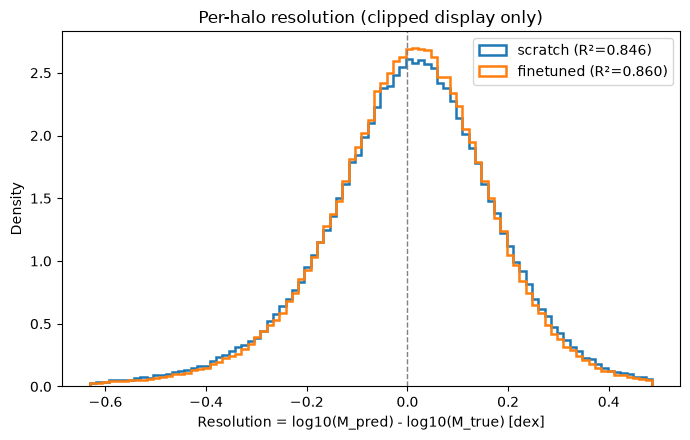

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
# Use common finite plotting range, without affecting statistics calculated above.
finite = np.concatenate([v[np.isfinite(v)] for v in resolutions.values()])
lo, hi = np.quantile(finite, [0.005, 0.995])
if hi <= lo: hi = lo + 1e-4
bins = np.linspace(lo, hi, 90)
for name, res in resolutions.items():
    ax.hist(res[np.isfinite(res)], bins=bins, histtype='step', density=True,
            label=f'{name} (R²={metrics.loc[name, "Global R² (log mass)"]:.3f})', linewidth=1.8)
ax.axvline(0, color='grey', ls='--', lw=1)
ax.set(xlabel='Resolution = log10(M_pred) - log10(M_true) [dex]', ylabel='Density',
       title='Per-halo resolution (clipped display only)')
ax.legend()
plt.tight_layout()
save_plot(fig, 'resolution_distribution')
plt.show()

## Scatter: predicted vs true halo mass

Each panel uses the same physical halos and axes. A random subset is plotted for speed; metrics always use the full selected sample.

Saved plots/predicted_vs_true_log_mass.png


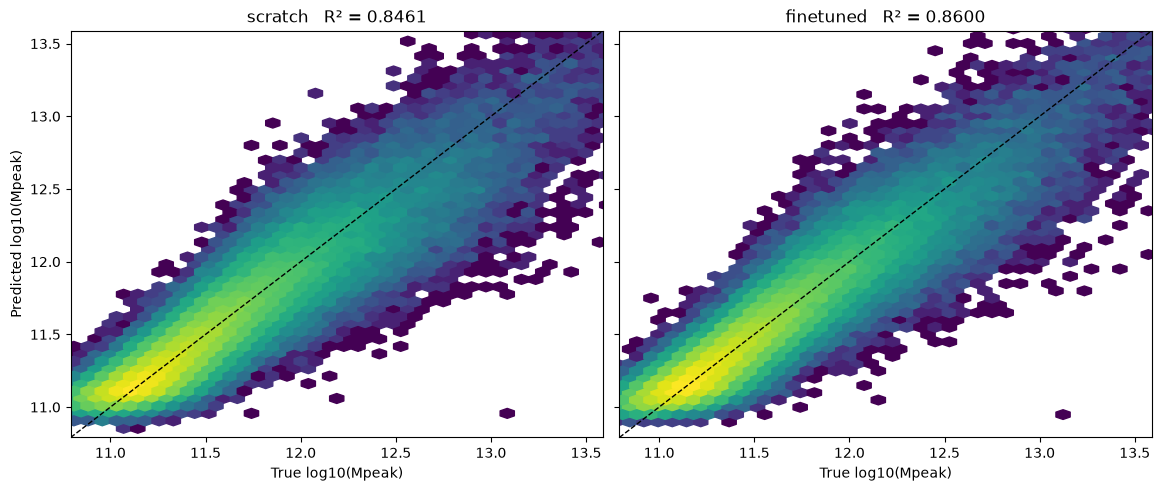

In [6]:
rng = np.random.default_rng(SEED)
idx = rng.choice(len(halos), size=min(MAX_SCATTER_POINTS, len(halos)), replace=False)
lims = np.quantile(np.concatenate([halos[c].to_numpy() for c in ('true','scratch','finetuned')]), [0.002,0.998])
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.8), sharex=True, sharey=True, constrained_layout=True)
for ax, name in zip(axs, ('scratch', 'finetuned')):
    ax.hexbin(halos['true'].to_numpy()[idx], halos[name].to_numpy()[idx], gridsize=65,
              mincnt=1, bins='log', cmap='viridis')
    ax.plot(lims, lims, '--', color='black', lw=1)
    ax.set(xlim=lims, ylim=lims, xlabel='True log10(Mpeak)',
           title=f'{name}   R² = {metrics.loc[name, "Global R² (log mass)"]:.4f}')
axs[0].set_ylabel('Predicted log10(Mpeak)')
save_plot(fig, 'predicted_vs_true_log_mass')
plt.show()

## Resolution versus true log mass

Median signed log-mass residual and 16th–84th percentile interval in each true-mass bin.

Saved plots/resolution_vs_true_log_mass.png


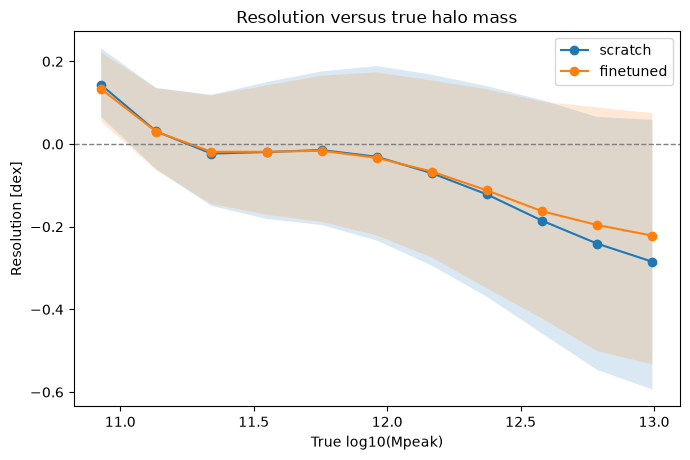

In [7]:
truth = halos['true'].to_numpy()
edges = np.linspace(*np.quantile(truth, [0.01, 0.99]), 12)
centres = 0.5 * (edges[:-1]+edges[1:])
fig, ax = plt.subplots(figsize=(7, 4.7))
for name, res in resolutions.items():
    med, low, high = [], [], []
    for i, (l, r) in enumerate(zip(edges[:-1], edges[1:])):
        v = res[(truth >= l) & ((truth < r) if i < len(centres)-1 else (truth <= r)) & np.isfinite(res)]
        if len(v) < 5:
            med.append(np.nan); low.append(np.nan); high.append(np.nan)
        else:
            a,b,c = np.quantile(v,[.16,.5,.84])
            med.append(b); low.append(a); high.append(c)
    med, low, high = map(np.asarray, (med,low,high))
    ax.plot(centres, med, marker='o', label=name)
    ax.fill_between(centres, low, high, alpha=.17)
ax.axhline(0, color='grey', ls='--', lw=1)
ax.set(xlabel='True log10(Mpeak)', ylabel='Resolution [dex]',
       title='Resolution versus true halo mass')
ax.legend()
plt.tight_layout()
save_plot(fig, 'resolution_vs_true_log_mass')
plt.show()

**Evaluator compatibility:** The per-halo analysis requires `mode='segmentation'`, because `regression` outputs one prediction per cloud (`N,...`) rather than one per halo (`N,M,1`). The evaluator already writes the point-wise target as `pid` for segmentation. The `file_id` mapping must match the source evaluation loader's `file_paths`; the notebook checks targets to prevent silent misalignment.

## RMSE versus true log mass

Unlike R² calculated *inside* a narrow true-mass bin, RMSE in dex remains interpretable when true mass varies little within the bin. The **global R²** for each model is reported in the metrics table above.

Saved plots/rmse_vs_true_log_mass.png


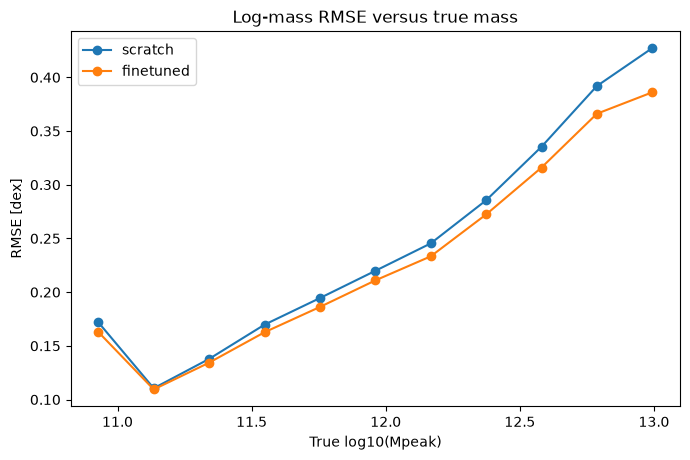

Halos per bin: [25633, 68169, 66378, 45347, 29633, 19039, 12478, 7954, 4955, 3211, 2003]


In [8]:
truth = halos['true'].to_numpy()
fig, ax = plt.subplots(figsize=(7, 4.7))
bin_counts = []
for name in ('scratch', 'finetuned'):
    vals, counts = [], []
    err = resolutions[name]
    for i, (left, right) in enumerate(zip(edges[:-1], edges[1:])):
        keep = (truth >= left) & ((truth < right) if i < len(centres)-1 else (truth <= right)) & np.isfinite(err)
        counts.append(int(keep.sum()))
        vals.append(np.sqrt(np.mean(err[keep] ** 2)) if keep.sum() >= 5 else np.nan)
    bin_counts.append(counts)
    ax.plot(centres, vals, marker='o', label=name)
ax.set(xlabel='True log10(Mpeak)', ylabel='RMSE [dex]', title='Log-mass RMSE versus true mass')
ax.legend()
plt.tight_layout()
save_plot(fig, 'rmse_vs_true_log_mass')
plt.show()
print('Halos per bin:', bin_counts[0])

## Prediction accuracy bands versus true log mass

Fraction of halos with absolute predicted log-mass error **≤0.2 dex**, **(0.2, 0.3] dex**, and **>0.3 dex**. All three fractions sum to one in each nonempty bin.

Saved plots/accuracy_bands_vs_true_log_mass.png


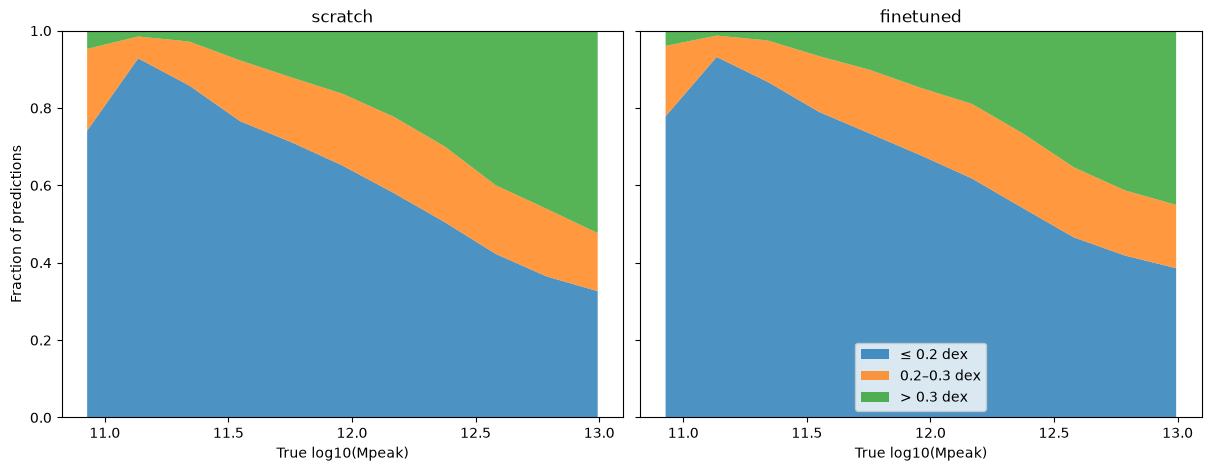

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True, sharey=True, constrained_layout=True)
labels = ['≤ 0.2 dex', '0.2–0.3 dex', '> 0.3 dex']
for ax, name in zip(axes, ('scratch', 'finetuned')):
    error = np.abs(halos[name].to_numpy() - truth)
    bands = np.full((3, len(centres)), np.nan)
    for i, (left, right) in enumerate(zip(edges[:-1], edges[1:])):
        keep = (truth >= left) & ((truth < right) if i < len(centres)-1 else (truth <= right))
        if keep.any():
            bands[:, i] = [(error[keep] <= .2).mean(),
                           ((error[keep] > .2) & (error[keep] <= .3)).mean(),
                           (error[keep] > .3).mean()]
    good = np.all(np.isfinite(bands), axis=0)
    ax.stackplot(centres[good], *bands[:, good], labels=labels, alpha=.8)
    ax.set(title=name, xlabel='True log10(Mpeak)', ylim=(0, 1))
axes[0].set_ylabel('Fraction of predictions')
axes[1].legend(loc='best')
save_plot(fig, 'accuracy_bands_vs_true_log_mass')
plt.show()

## Resolution versus true log mass: central versus satellite halos

`global[..., 0]` is the only auxiliary channel, `is_central_mass` (`1` = central, `0` = satellite). Each panel compares scratch and fine-tuned models with median resolution and the 16th–84th percentile range.

Saved plots/central_satellite_resolution_vs_true_log_mass.png


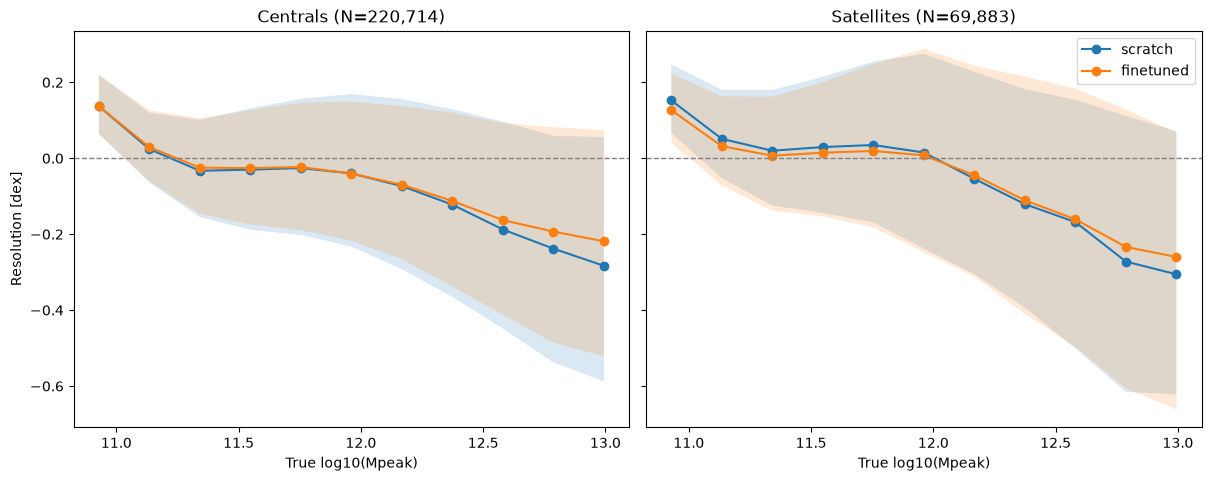

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), sharex=True, sharey=True, constrained_layout=True)
for ax, (title, central_value) in zip(axes, [('Centrals', True), ('Satellites', False)]):
    sub = halos['central'].to_numpy() == central_value
    for name, res in resolutions.items():
        med, lo, hi = [], [], []
        for i, (left, right) in enumerate(zip(edges[:-1], edges[1:])):
            keep = sub & (truth >= left) & ((truth < right) if i < len(centres)-1 else (truth <= right)) & np.isfinite(res)
            if keep.sum() < 5:
                med.append(np.nan); lo.append(np.nan); hi.append(np.nan)
            else:
                a, b, c = np.quantile(res[keep], [.16, .5, .84])
                med.append(b); lo.append(a); hi.append(c)
        ax.plot(centres, med, marker='o', label=name)
        ax.fill_between(centres, lo, hi, alpha=.17)
    ax.axhline(0, color='grey', ls='--', lw=1)
    ax.set(title=f'{title} (N={sub.sum():,})', xlabel='True log10(Mpeak)')
axes[0].set_ylabel('Resolution [dex]')
axes[1].legend()
save_plot(fig, 'central_satellite_resolution_vs_true_log_mass')
plt.show()